In [1]:
x=1

In [11]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [12]:
df = pd.read_csv('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/reports/best_imc.tsv', sep='\t', index_col=None)

In [13]:
np.unique(df['task'])

array(['imc', 'imc_grade', 'imc_grade_no_met', 'imc_survival',
       'imc_survival_death_by_primary_alive'], dtype=object)

In [14]:
task = 'imc_grade_no_met'

In [15]:
runs = {}
yerr = {}
df_task = df[df['task'] == task]
for method in np.unique(df_task['method']):
    runs[method] = eval(df_task.loc[df_task['method'] == method, 'accuracies'].values[0])
    yerr[method] = np.array(runs[method]).std()

df_tmp = df_task[['method', 'accuracy']]
df_tmp.index = df_tmp['method']
df_tmp = df_tmp[['accuracy']].sort_values('accuracy', ascending=False)
df_tmp = df_tmp.T

yerr_sorted = [yerr[method] for method in df_tmp.columns]

In [16]:
df_tmp.columns

Index(['multigrate_mil', 'gex_rf', 'pb_rf', 'gex_nn', 'ct_pb_rf', 'pb_mr',
       'pb_nn', 'ct_pb_nn', 'ct_pb_mr', 'freq_rf', 'freq_nn', 'freq_mr'],
      dtype='object', name='method')

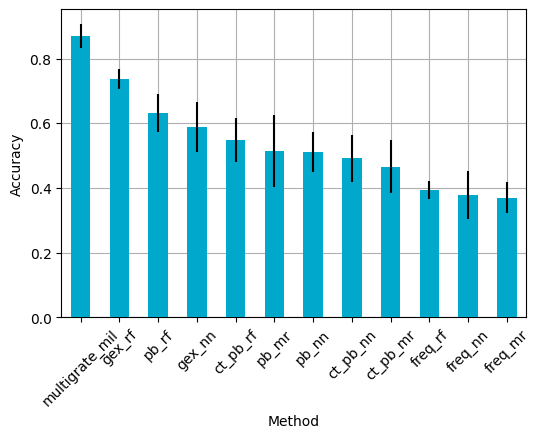

In [19]:
ax = df_tmp.T.plot(kind='bar', zorder=3, figsize=(6, 4), color=["#00a8cc"], rot=45, yerr=yerr_sorted)
ax.get_legend().remove()
ax.grid(zorder=0)
plt.xlabel('Method')
plt.ylabel('Accuracy')
plt.title('')
plt.savefig('figures/imc_grade_no_met.svg', bbox_inches='tight')

In [ ]:
df_tmp

method,multigrate_mil,gex_rf,pb_rf,gex_nn,ct_pb_rf,pb_mr,pb_nn,ct_pb_nn,ct_pb_mr,freq_rf,freq_nn,freq_mr
accuracy,0.869771,0.737756,0.631554,0.589095,0.548742,0.514369,0.51149,0.491402,0.465476,0.392863,0.377785,0.370133
